# 1 - Logistic Regression
In this notebook, a logistic regression model will be used for forecasting electricity prices in Spain.

First, we import the required libraries for data handling, normalization, numerical computation, and visualization.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Set random seed for consistent results
np.random.seed(42)

# 2 - Dataset Loading and Chronological Split
We load `Master_Dataset_Engineered_2023_2025.xlsx` (26,136 hourly observations) and divide it chronologically into:
- **Training Set (2023–2024):** First 17,376 rows (`2023-01-08 00:00` to `2024-12-31 23:00`).
- **Testing Set (2025):** Last 8,760 rows (`2025-01-01 00:00` to `2025-12-31 23:00`).

Column `1` (`Price_EUR_MWh`) is extracted as the target output `y`, and columns `2` to `13` (12 engineered features) are extracted as the input matrix `x`.

In [16]:
# Load the data
df = pd.read_excel("C:\ProjecteAIApplications\model_input\Master_Dataset_Engineered_2023_2025.xlsx")

#Separate the data 
input_data = df.iloc[:17376].values
input_data_2025 = df.iloc[17376:].values

# Categorizing the data into inputs (x) and outputs (y) for train and test sets
# Column 0: Datetime, Column 1: Price_EUR_MWh (y), Columns 2 to 13: x
train_set_x_orig = input_data[:, 2:].astype(float)
test_set_x_orig = input_data_2025[:, 2:].astype(float)

train_set_y_orig = input_data[:, 1:2].astype(float)
test_set_y_orig = input_data_2025[:, 1:2].astype(float)

print(f"train_set_x_orig shape: {train_set_x_orig.shape}")
print(f"train_set_y_orig shape: {train_set_y_orig.shape}")
print(f"test_set_x_orig shape:  {test_set_x_orig.shape}")
print(f"test_set_y_orig shape:  {test_set_y_orig.shape}")

train_set_x_orig shape: (17376, 12)
train_set_y_orig shape: (17376, 1)
test_set_x_orig shape:  (8760, 12)
test_set_y_orig shape:  (8760, 1)


# 3 -Normalization
To ensure stable gradient descent convergence and prevent large-magnitude variables from dominating the weights, we scale all features and target values to the (0, 1) range using MinMaxScaler.

We then transpose each array so that its dimensions follow the neural network convention (n_features, m_samples).

In [17]:

scaler = MinMaxScaler(feature_range=(0, 1))

train_set_x_normalized = scaler.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler.fit_transform(test_set_x_orig)

train_set_y_normalized = scaler.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler.fit_transform(test_set_y_orig)

# Transpose arrays so features are in rows and hourly samples are in columns
train_set_x_normalized = train_set_x_normalized.T
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T

# Extract dataset dimensions
m_train = train_set_x_normalized.shape[1]
m_test = test_set_x_normalized.shape[1]
n_x = train_set_x_normalized.shape[0]

print(f"Number of training samples (m_train): {m_train}")
print(f"Number of testing samples (m_test):   {m_test}")
print(f"Number of input features (n_x):       {n_x}")
print(f"train_set_x_normalized shape:         {train_set_x_normalized.shape}")
print(f"train_set_y_normalized shape:         {train_set_y_normalized.shape}")

Number of training samples (m_train): 17376
Number of testing samples (m_test):   8760
Number of input features (n_x):       12
train_set_x_normalized shape:         (12, 17376)
train_set_y_normalized shape:         (1, 17376)


# 4 - Model Architecture Functions
## 4.1 - Activation Function and Parameter Initialization
We define the sigmoid activation function to map linear combinations into the $(0, 1)$ interval, along with a helper function to initialize the weight vector W with random real numbers and bias b to zero.

In [18]:
def sigmoid(z):

    s = 1/(1 + np.exp(-z))

    return s

def init_params(n_features):

    w = np.zeros((n_features, 1))
    b = 0.0
    
    return w, b

## 4.2 - Forward and backward prop


In [19]:
def propagate(w, b, X, Y):
    """Executes forward and backward propagation using vectorized matrix operations."""
    m = X.shape[1] #number of columns = number of examples
    
    # Forward pass: compute activation and cost
    z = np.dot(w.T, X) + b #WX +b;     W = (nx, 1)    X = (nx,m)  That is why we need to traspose W, to allow matricial product

    A = sigmoid(z)

    cost = (-1 / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))
    
    # Backward pass: compute gradients with respect to w and b
    dZ = A - Y
    dw = (1 / m) * np.dot(X, dZ.T)
    db = (1 / m) * np.sum(dZ)
    
    cost = float(np.squeeze(cost))
    grads = {"dw": dw, "db": db}
    
    return grads, cost

## 4.3 - Gradient descent optimization
Here, we are updating the parameters using the gradient descent method

In [20]:
def optimize(w, b, X, Y, num_iterations=2000, learning_rate=0.5, print_cost=False):
    costs = []
    
    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        
        # Gradient descent parameter update
        w = w - learning_rate * grads["dw"]
        b = b - learning_rate * grads["db"]
        
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print ("Cost after iteration %i: %f" %(i, cost))
                
    params = {"w": w, "b": b}
    
    return params, grads, costs



# 6 - Prediction
Usint the learned parameters, we are going to build the function that will predict the labels for our dataset

In [21]:
def predict (w, b, X):
    
    m = X.shape[1]
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1) #We ensure that W has the correct dimensions (nx, 1) (number of features, number of neurons)

    z = np.dot(w.T, X) + b 
    A = sigmoid(z)

    for i in range(A.shape[1]):
        Y_prediction[0,i] = A[0,i]
    
    return Y_prediction


# 5 - Model training
Implement the model function using all the previously defined functions

In [22]:

def model(X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.5, print_cost=True):
    

    w, b = init_params(X_train.shape[0]) #Initializing w and b
    
    params, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    w, b = params["w"], params["b"]
    
    Y_pred_train = predict(w, b, X_train)
    Y_pred_test = predict(w, b, X_test)
    
    if print_cost:
        print("Train accuracy: {} %".format(100- np.mean(np.abs(Y_pred_train - Y_train))*100))
        print("Test accuracy: {} %".format(100-np.mean(np.abs(Y_pred_test - Y_test))*100))
    
    results = {
        "costs": costs,
        "Y_pred_train": Y_pred_train,
        "Y_pred_test": Y_pred_test,
        "w": w,
        "b": b,
        "learning_rate": learning_rate,
        "num_iterations": num_iterations
    }

    return results


In [23]:
logistic_regression_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, num_iterations = 2000, learning_rate = 0.5, print_cost = True)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.576147
Cost after iteration 200: 0.568262
Cost after iteration 300: 0.565678
Cost after iteration 400: 0.564418
Cost after iteration 500: 0.563709
Cost after iteration 600: 0.563279
Cost after iteration 700: 0.563007
Cost after iteration 800: 0.562828
Cost after iteration 900: 0.562707
Cost after iteration 1000: 0.562623
Cost after iteration 1100: 0.562564
Cost after iteration 1200: 0.562522
Cost after iteration 1300: 0.562491
Cost after iteration 1400: 0.562468
Cost after iteration 1500: 0.562451
Cost after iteration 1600: 0.562438
Cost after iteration 1700: 0.562428
Cost after iteration 1800: 0.562420
Cost after iteration 1900: 0.562414
Train accuracy: 92.84556025147106 %
Test accuracy: 93.72388590850758 %


# Cost function
Plot of the cost function 

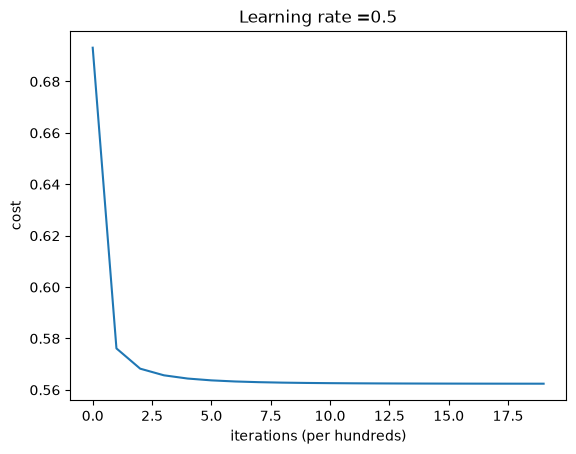

In [24]:
costs = np.squeeze(logistic_regression_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)') #the reason of this way of plotting is the way we defined optimize function (Only stores a value for cost every 100 iterations)
plt.title("Learning rate =" + str(logistic_regression_model["learning_rate"]))
plt.show()

# Denormalizing 

In [25]:
#Reverse normalization
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Reverse the normalization to get the original data
Y_prediction_test_real_scale = scaler.inverse_transform(logistic_regression_model["Y_pred_test"])


# Results

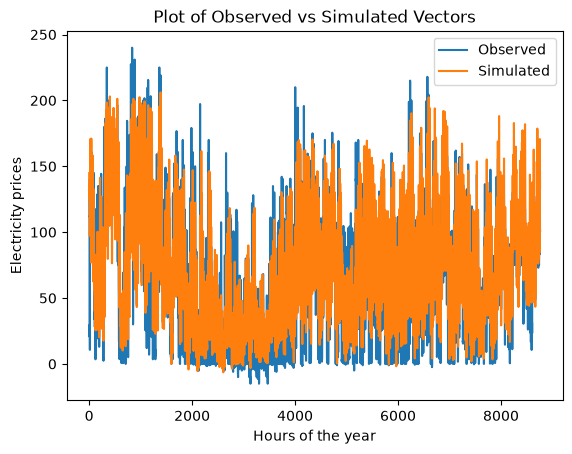

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Define the two vectors

x = np.arange(0,8760, 1)
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale.T


# Plot the vectors
plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')

# Add a title and labels for the x and y axes
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Hours of the year')
plt.ylabel('Electricity prices')

# Set the y-axis limits
plt.ylim()

# Add a legend
plt.legend()

# Display the plot
plt.show()

In [27]:
feature_names = df.columns[2:].tolist()

weights_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight": logistic_regression_model["w"].flatten()
})

print(weights_df)


                  Feature    Weight
0        Load_Forecast_MW  1.161740
1     Hydro_Reservoir_MWh -0.484755
2   Nuclear_Generation_MW  0.127684
3         Wind_Onshore_MW -2.076608
4                Solar_MW -1.096755
5              Price_t_24  1.398893
6              Price_t_48  0.294448
7             Price_t_168  0.993082
8            Price_24h_MA  0.356212
9                    Hour  0.028171
10                  Month  0.068228
11             Is_Weekend -0.199594


# 7 - Hyperparameter Optimization 
First, Grid Search

In [28]:
print(train_set_x_orig.shape[1])

12


In [29]:


#define the data we will use for validation

#First half for hyperparameter optimization, second half for test the best combination

X_val_norm = test_set_x_normalized[:, :4380]
Y_val_norm = test_set_y_normalized[:, :4380]
y_val_orig = test_set_y_orig[:4380, :]

#Second half:

X_test_final_norm = test_set_x_normalized[:, 4380:] 
Y_test_final_norm = test_set_y_normalized[:, 4380:]
y_test_final_orig = test_set_y_orig[4380:, :]

#we define the different hyperparameters we will try with

learning_rates = [0.01, 0.025, 0.1, 0.5, 0.75, 0.85, 1.0]
iterations_list = [500, 1000, 2000, 3000]

#we will save the results in this list:

grid_results = []

#loop for grid search

for lr in learning_rates:
    for n_iter in iterations_list:

        w, b = init_params(train_set_x_orig.shape[1])
        params, grads, cost = optimize(w, b, train_set_x_normalized, train_set_y_normalized, num_iterations = n_iter, learning_rate = lr, print_cost = False)
        
        #then, we predict in the train (23-24) and in validation (first half 2025)

        Y_pred_train = predict(params["w"], params["b"], train_set_x_normalized) 
        Y_pred_val   = predict(params["w"], params["b"], X_val_norm)

        #we calculate accuracy and MAE/RMSE in first half 2025

        train_acc = 100 -np.mean(np.abs(Y_pred_train - train_set_y_normalized))*100
        val_acc = 100 - np.mean(np.abs(Y_pred_val - Y_val_norm))*100

        y_pred_val_eur = scaler.inverse_transform(Y_pred_val.T)
        val_mae  = np.mean(np.abs(y_pred_val_eur - y_val_orig))
        val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))

        grid_results.append({
            "Learning_Rate": lr,
            "Iterations": n_iter,
            "Final_Cost": cost[-1],
            "Train_Acc (%)": round(train_acc, 2),
            "Val_Acc (%)": round(val_acc, 2),
            "Val_MAE (EUR/MWh)": round(val_mae, 2),
            "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
        })

df_grid = pd.DataFrame(grid_results)
best_row = df_grid.loc[df_grid["Val_MAE (EUR/MWh)"].idxmin()]

print(df_grid.to_string(index = False))
print("Best hyperparameters in validation (1st Half 2025):  ")
print(best_row)



 Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
         0.010         500    0.635559          84.45        82.39              44.91               50.79
         0.010        1000    0.618512          86.10        84.47              39.60               44.68
         0.010        2000    0.598095          88.35        87.29              32.41               36.83
         0.010        3000    0.587108          89.69        89.03              27.98               32.37
         0.025         500    0.615786          86.79        85.32              37.44               42.27
         0.025        1000    0.593510          89.10        88.26              29.93               34.29
         0.025        2000    0.577067          91.04        90.85              23.34               28.07
         0.025        3000    0.571279          91.75        91.84              20.82               25.88
         0.100         500    0.580135        

# 8 - Feature Importance Study
## 8.1 - Feature Importance by Model Weights ($|w|$)
Since I don't know how to use plotting, I used AI for this part

FEATURE IMPORTANCE RANKING (LOGISTIC REGRESSION):
              Feature  Weight  Abs_Weight  Relative_Importance (%)              Effect
      Wind_Onshore_MW -2.0766      2.0766                  25.0611 Decreases Price (-)
           Price_t_24  1.3989      1.3989                  16.8823 Increases Price (+)
     Load_Forecast_MW  1.1617      1.1617                  14.0202 Increases Price (+)
             Solar_MW -1.0968      1.0968                  13.2360 Decreases Price (-)
          Price_t_168  0.9931      0.9931                  11.9848 Increases Price (+)
  Hydro_Reservoir_MWh -0.4848      0.4848                   5.8502 Decreases Price (-)
         Price_24h_MA  0.3562      0.3562                   4.2989 Increases Price (+)
           Price_t_48  0.2944      0.2944                   3.5535 Increases Price (+)
           Is_Weekend -0.1996      0.1996                   2.4088 Decreases Price (-)
Nuclear_Generation_MW  0.1277      0.1277                   1.5409 Increases Pri

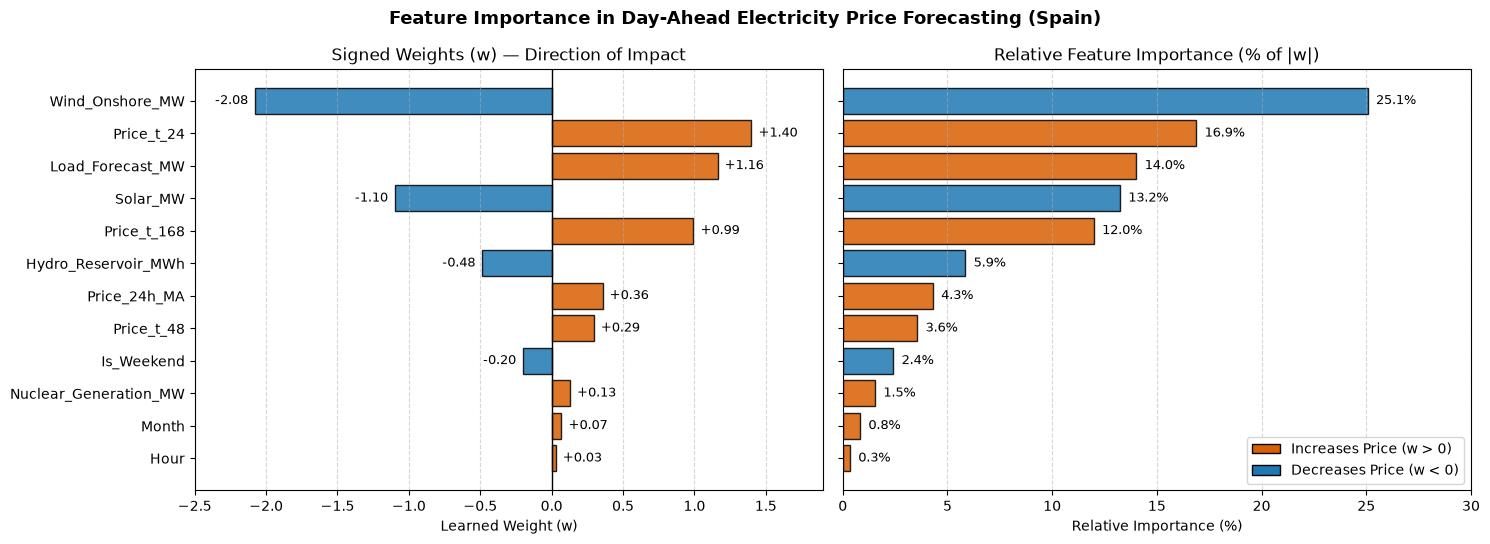

In [30]:
# 1. Compute absolute weight and relative importance (%) from weights_df
importance_df = weights_df.copy()
importance_df["Abs_Weight"] = importance_df["Weight"].abs()
importance_df["Relative_Importance (%)"] = (
    importance_df["Abs_Weight"] / importance_df["Abs_Weight"].sum() * 100.0
)
importance_df["Effect"] = np.where(
    importance_df["Weight"] >= 0, "Increases Price (+)", "Decreases Price (-)"
)

# Sort from most important to least important
importance_df = importance_df.sort_values(by="Abs_Weight", ascending=False).reset_index(drop=True)

print("FEATURE IMPORTANCE RANKING (LOGISTIC REGRESSION):")
print("=" * 78)
print(importance_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("=" * 78)

# 2. Horizontal Bar Chart of Feature Importance
plot_df = importance_df.sort_values(by="Abs_Weight", ascending=True)
colors = ["#d95f02" if w >= 0 else "#1f78b4" for w in plot_df["Weight"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

# Left plot: Signed Weights (Direction + Magnitude)
bars1 = axes[0].barh(plot_df["Feature"], plot_df["Weight"], color=colors, edgecolor="black", alpha=0.85)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("Signed Weights (w) — Direction of Impact")
axes[0].set_xlabel("Learned Weight (w)")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)
axes[0].set_xlim(-2.5, 1.9)
for bar in bars1:
    w_val = bar.get_width()
    offset = 0.05 if w_val >= 0 else -0.05
    ha = "left" if w_val >= 0 else "right"
    axes[0].text(w_val + offset, bar.get_y() + bar.get_height()/2, f"{w_val:+.2f}", va="center", ha=ha, fontsize=9)

# Right plot: Relative Importance (% of total |w|)
bars2 = axes[1].barh(plot_df["Feature"], plot_df["Relative_Importance (%)"], color=colors, edgecolor="black", alpha=0.85)
axes[1].set_title("Relative Feature Importance (% of |w|)")
axes[1].set_xlabel("Relative Importance (%)")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)
axes[1].set_xlim(0, 30)
for bar in bars2:
    pct_val = bar.get_width()
    axes[1].text(pct_val + 0.4, bar.get_y() + bar.get_height()/2, f"{pct_val:.1f}%", va="center", ha="left", fontsize=9)

# Legend for direction
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#d95f02", edgecolor="black", label="Increases Price (w > 0)"),
    Patch(facecolor="#1f78b4", edgecolor="black", label="Decreases Price (w < 0)")
]
axes[1].legend(handles=legend_handles, loc="lower right")

plt.suptitle("Feature Importance in Day-Ahead Electricity Price Forecasting (Spain)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()